# 0. データ取得

下記データを用いる

| データ | 入手元 | 用途 |
|---|---|---|
| Grabette実演データセット`grabette_pick3_cartesian_480` | HuggingFace: <https://huggingface.co/datasets/SteveNguyen/grabette_pick3_cartesian_480> | 人が手持ちグリッパーで物体を掴んだ動作（位置・姿勢の変化量、グリッパー角、手元カメラ映像） |
| SO-101のMuJoCoモデル`robotstudio_so101` | GitHub: <https://github.com/google-deepmind/mujoco_menagerie>の`robotstudio_so101/` | 関節構成・形状・可動範囲。順運動学/逆運動学の計算とシミュレーション描画に使う |

- Grabetteデータセットはリビジョン`d46306f6a58e7c83c144ee41af4e893b788d6f9f`を用いる
- mujoco_menagerieはコミット`ac6b2b09983786f3036cab1000221017fa2193b4`を用いる

In [1]:
# パス設定
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"        # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"      # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

## 1. Grabetteデータセットの取得

`grabette_pick3_cartesian_480`は、554エピソードの缶・マスタード容器・カップの3種類の物体を掴むデータセット

In [2]:
from huggingface_hub import snapshot_download
# 入手元: https://huggingface.co/datasets/SteveNguyen/grabette_pick3_cartesian_480

GRABETTE_REPO_ID = "SteveNguyen/grabette_pick3_cartesian_480"
GRABETTE_REVISION = "d46306f6a58e7c83c144ee41af4e893b788d6f9f"

snapshot_download(
    repo_id=GRABETTE_REPO_ID,
    repo_type="dataset",
    revision=GRABETTE_REVISION,
    local_dir=str(GRABETTE_DIR),
);
# print("取得先:", GRABETTE_DIR)

In [3]:
# データセットの概要（meta/info.json）を確認する
import json

with open(GRABETTE_DIR / "meta" / "info.json") as f:
    grabette_info = json.load(f)

print("保存形式   :", grabette_info["codebase_version"])
print("フレームレート:", grabette_info["fps"], "fps")
print("エピソード数:", grabette_info["total_episodes"])
print("総フレーム数:", grabette_info["total_frames"])
print()
print("記録されている項目（features）:")
for key, feature in grabette_info["features"].items():
    print(f"  {key:26s} dtype={feature['dtype']:8s} shape={feature['shape']}")

保存形式   : v3.0
フレームレート: 50 fps
エピソード数: 554
総フレーム数: 91123

記録されている項目（features）:
  observation.images.cam0    dtype=video    shape=[3, 360, 480]
  action                     dtype=float32  shape=[11]
  is_lost                    dtype=float32  shape=[1]
  timestamp                  dtype=float32  shape=[1]
  frame_index                dtype=int64    shape=[1]
  episode_index              dtype=int64    shape=[1]
  index                      dtype=int64    shape=[1]
  task_index                 dtype=int64    shape=[1]
  observation.state          dtype=float32  shape=[2]


`action`は11次元で、各列の意味は`names`に記録されている
（dx, dy, dz, dr6d_0〜5, proximal, distal）。
各列の意味と使い方は01で詳しく確認する。

## 2. SO-101 MuJoCoモデルの取得

SO-101のMuJoCo用のモデルは、Google DeepMindが公開しているmujoco_menagerieに収録されている。
サイズの関係上`robotstudio_so101/`ディレクトリだけをDL

In [4]:
# 入手元: https://github.com/google-deepmind/mujoco_menagerie
!git clone -q --filter=blob:none --no-checkout https://github.com/google-deepmind/mujoco_menagerie.git data/mujoco_menagerie
!git -C data/mujoco_menagerie sparse-checkout set robotstudio_so101
!git -C data/mujoco_menagerie checkout -q ac6b2b09983786f3036cab1000221017fa2193b4 2>&1 | cat

In [5]:
# 取得したモデルをMuJoCoで読み込めるか確認
import mujoco

so101_model = mujoco.MjModel.from_xml_path(str(MJCF_PATH))
print("関節数 :", so101_model.njnt)
for j in range(so101_model.njnt):
    name = mujoco.mj_id2name(so101_model, mujoco.mjtObj.mjOBJ_JOINT, j)
    low, high = so101_model.jnt_range[j]
    print(f"  {j}: {name:14s} 可動範囲[{low:+.3f}, {high:+.3f}] rad")

関節数 : 6
  0: shoulder_pan   可動範囲[-1.920, +1.920] rad
  1: shoulder_lift  可動範囲[-1.745, +1.745] rad
  2: elbow_flex     可動範囲[-1.690, +1.690] rad
  3: wrist_flex     可動範囲[-1.658, +1.658] rad
  4: wrist_roll     可動範囲[-2.744, +2.744] rad
  5: gripper        可動範囲[-0.175, +1.745] rad


## 3. 取得データの目視確認

取得したデータを並べて表示し、正しく読み込めていることを目視確認

- 左: Grabetteの手元カメラ映像（エピソード1の最初のフレーム）
- 右: SO-101モデル（全関節0の姿勢）をMuJoCoで描画したもの

In [6]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

エピソード1: file-000.mp4の4.24秒目から開始


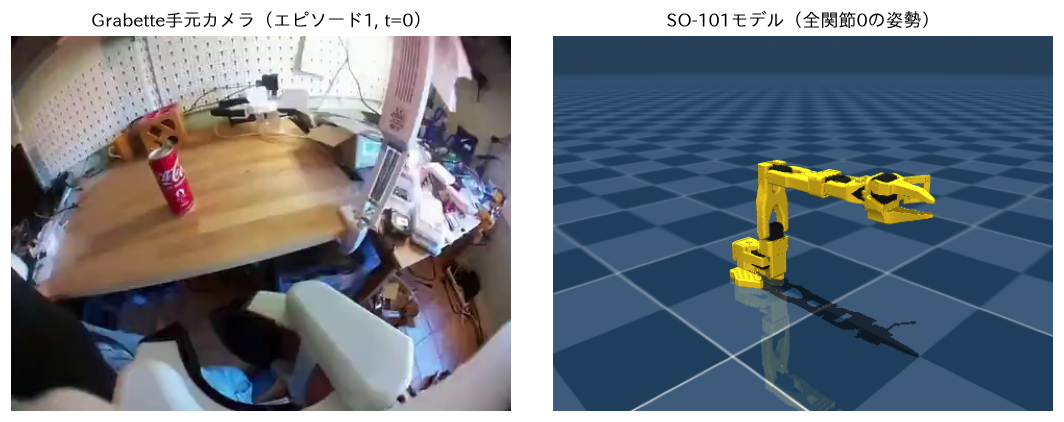

In [7]:
# ------------------------------------------------------------
# Grabette映像の1フレームを取り出す
# ------------------------------------------------------------
# Grabetteの動画は、複数エピソードが1本のmp4につながって保存されている。
# 各エピソードが「何番目のmp4の、何秒目から始まるか」は、
# meta/episodes/のエピソード情報に記録されている。
import pandas as pd
from lerobot.datasets.video_utils import decode_video_frames_pyav

VIDEO_KEY = "observation.images.cam0" # カメラのキー
episodes_meta = pd.read_parquet(
    GRABETTE_DIR / "meta" / "episodes" / "chunk-000" / "file-000.parquet"
).set_index("episode_index") # メタデータについて、エピソードインデックスをキーに設定

episode_id = 1
row = episodes_meta.loc[episode_id]
video_path = (GRABETTE_DIR / "videos" / VIDEO_KEY
              / f"chunk-{int(row[f'videos/{VIDEO_KEY}/chunk_index']):03d}"
              / f"file-{int(row[f'videos/{VIDEO_KEY}/file_index']):03d}.mp4")
start_time = float(row[f"videos/{VIDEO_KEY}/from_timestamp"])
print(f"エピソード{episode_id}: {video_path.name}の{start_time:.2f}秒目から開始")

# 指定時刻のフレームを(N, C, H, W)のuint8で取り出し、(H, W, C)に並べ替える
frames = decode_video_frames_pyav(video_path, [start_time],
                                  tolerance_s=1.5 / 50, return_uint8=True)
frame = frames[0].permute(1, 2, 0).numpy()

# ------------------------------------------------------------
# SO-101を描画する
# ------------------------------------------------------------
# 描画には、so101.xmlに床と照明を足したscene.xml（同じリポジトリに含まれる）を使う
scene_model = mujoco.MjModel.from_xml_path(str(SCENE_PATH))
scene_data = mujoco.MjData(scene_model)
mujoco.mj_forward(scene_model, scene_data)   # 全関節0の姿勢で位置を計算
camera = mujoco.MjvCamera()
camera.azimuth, camera.elevation, camera.distance = 135.0, -20.0, 0.8
camera.lookat[:] = (0.15, 0.0, 0.15)
with mujoco.Renderer(scene_model, height=360, width=480) as renderer:
    renderer.update_scene(scene_data, camera=camera)
    so101_image = renderer.render()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].imshow(frame)
axes[0].set_title("Grabette手元カメラ（エピソード1, t=0）")
axes[1].imshow(so101_image)
axes[1].set_title("SO-101モデル（全関節0の姿勢）")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "00_data_preview.png", bbox_inches="tight")
plt.show()